# 10 · Geometría y polaridad de la pista

La clase `Track` representa una pista unidimensional de sitios igualmente espaciados. Compararemos las coordenadas para las dos orientaciones de polaridad.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from protein_motor_sim.core.track import Track

plus_track = Track(name="microtubule_plus", lattice_spacing_nm=8.2, polarity=1)
minus_track = Track(name="microtubule_reversed", lattice_spacing_nm=8.2, polarity=-1)
indices = np.arange(-5, 6)
plus_positions = [plus_track.site_position_nm(int(i)) for i in indices]
minus_positions = [minus_track.site_position_nm(int(i)) for i in indices]

## 1. Coordenadas de los sitios

In [3]:
print("Índice | Pista + (nm) | Pista - (nm)")
for i, xp, xm in zip(indices, plus_positions, minus_positions):
    print(f"{i:6d} | {xp:12.2f} | {xm:12.2f}")

Índice | Pista + (nm) | Pista - (nm)
    -5 |       -41.00 |        41.00
    -4 |       -32.80 |        32.80
    -3 |       -24.60 |        24.60
    -2 |       -16.40 |        16.40
    -1 |        -8.20 |         8.20
     0 |         0.00 |         0.00
     1 |         8.20 |        -8.20
     2 |        16.40 |       -16.40
     3 |        24.60 |       -24.60
     4 |        32.80 |       -32.80
     5 |        41.00 |       -41.00


## 2. Visualización de las dos orientaciones

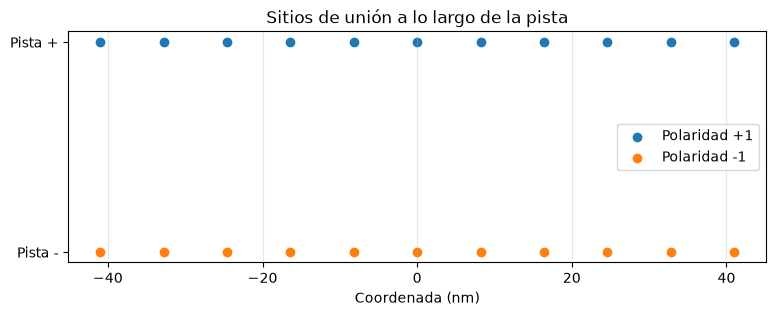

In [4]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.scatter(plus_positions, np.ones(len(indices)), label="Polaridad +1")
ax.scatter(minus_positions, np.zeros(len(indices)), label="Polaridad -1")
ax.set_yticks([0, 1], ["Pista -", "Pista +"])
ax.set_xlabel("Coordenada (nm)")
ax.set_title("Sitios de unión a lo largo de la pista")
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.show()

## 3. Encontrar el sitio más cercano

In [5]:
position_nm = 24.0
index = plus_track.nearest_site_index(position_nm)
print(f"Posición consultada: {position_nm:.2f} nm")
print(f"Índice del sitio más cercano: {index}")
print(f"Coordenada del sitio: {plus_track.site_position_nm(index):.2f} nm")

Posición consultada: 24.00 nm
Índice del sitio más cercano: 3
Coordenada del sitio: 24.60 nm


**Nota:** la pista actual es una aproximación unidimensional. Un microtúbulo real tiene una estructura cilíndrica con protofilamentos y sitios discretos; esa geometría más completa podría incorporarse en una versión posterior.